# Entrega 2 — Descripción del dataset y origen

**Proyecto:** anticipar qué divisiones de la industria manufacturera argentina van a estar en contracción interanual dentro de 3 meses.
**Alumna:** Mónica Frías — Aprendizaje Automático, 2026.

Este notebook hace todo lo necesario antes de entrenar modelos:

1. Carga los archivos originales tal como se descargaron (INDEC y BCRA) y muestra por qué no se pueden usar directamente.
2. Aplica las transformaciones (scripts de `Parcial/src/`) y arma la tabla **división × mes**.
3. Describe el dataset final: instancias, columnas, tipos, faltantes.
4. Analiza la variable objetivo.
5. Implementa la **disponibilidad temporal** de los datos (devolución de la Entrega 1).
6. Define el modelo de referencia.
7. Explora la relación entre las predictoras y la variable objetivo, **usando solo el período de entrenamiento**.

La documentación completa (fuentes, enlaces, fechas de descarga y limitaciones) está en [`Parcial/README.md`](../README.md).

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PARCIAL = Path("..").resolve()          # carpeta Parcial/ (el notebook está en Parcial/notebooks/)
RAW = PARCIAL / "data" / "raw"
PROCESSED = PARCIAL / "data" / "processed"
EXTERNAL = PARCIAL / "data" / "external"
sys.path.append(str(PARCIAL / "src"))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

## 1. Archivos originales

| Archivo | Contenido | Fuente | Período |
|---|---|---|---|
| `sh_ipi_manufacturero_2026.xls` | Índice de producción industrial manufacturero (IPI) por división, base 2004=100 | INDEC | ene-2016 a ago-2026 |
| `sh_capacidad_09_26.xls` | Utilización de la capacidad instalada: nivel general y 12 bloques sectoriales (%) | INDEC | ene-2016 a jul-2026 |
| `balanmensual.xls` | Exportaciones e importaciones mensuales (millones de USD) | INDEC | ene-1990 a sep-2026 |
| `com3500.xls` | Tipo de cambio mayorista de referencia (Com. A 3500), diario | BCRA | mar-2002 a oct-2026 |
| `series.xlsm` | Series monetarias; se usa la hoja *TASAS DE MERCADO* (BADLAR) | BCRA | ene-2003 a oct-2026 |

Los archivos están guardados **sin modificar** en `data/raw/`.

In [2]:
pd.DataFrame([{"archivo": f.name, "tamaño (KB)": round(f.stat().st_size / 1024)}
              for f in sorted(RAW.iterdir()) if f.is_file()])

,archivo,tamaño (KB)
0,balanmensual.xls,192
1,com3500.xls,380
2,series.xlsm,7831
3,sh_capacidad_09_26.xls,56
4,sh_ipi_manufacturero_2026.xls,974


### Cómo vienen los datos

Son planillas pensadas para leer en pantalla, no para procesar: títulos y notas mezclados con los datos, encabezados repartidos en varias filas, el año escrito una sola vez, asteriscos de "dato provisorio" y algunos errores de tipeo. Algunos ejemplos:

**IPI manufacturero (hoja *Cuadro 2*):** los códigos de división están en la fila 2, los nombres en la fila 3, y el año aparece solo en enero.

In [3]:
ipi_crudo = pd.read_excel(RAW / "sh_ipi_manufacturero_2026.xls", sheet_name="Cuadro 2", header=None)
print("Filas x columnas:", ipi_crudo.shape)
ipi_crudo.iloc[:9, :6]

Filas x columnas: (136, 88)


,0,1,2,3,4,5
0,"Cuadro 2. IPI manufacturero nivel general, div...",NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,Código (CLaNAE 2004),NaN,NaN,D,15,15111
3,Período,NaN,NaN,IPI Manufacturero,Alimentos y bebidas,Carne vacuna
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,6,2016,Enero,117.051194,130.676161,83.169668
7,7,NaN,Febrero,118.900294,129.263973,79.919338
8,8,NaN,Marzo,136.80623,141.650623,88.923323


El cuadro tiene muchas más columnas que las 16 divisiones, porque incluye también las subclases. El script se queda solo con las divisiones.

**Capacidad instalada:** el año va en una fila aparte ("Año 2016"), los meses llevan asterisco y al final hay notas al pie.

In [4]:
cap_crudo = pd.read_excel(RAW / "sh_capacidad_09_26.xls", header=None)
cap_crudo.iloc[7:13, :4]

,0,1,2,3
7,Año 2016,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN
9,Enero*,62.9,68.5,83.9
10,Febrero*,64.2,66.8,81.3
11,Marzo*,64.8,67.2,84.1
12,Abril*,64.8,63.5,81.4


**Balanza comercial:** el año lleva asterisco ("2026*") y hay un error de tipeo en el mes de septiembre de 2026.

In [5]:
bal_crudo = pd.read_excel(RAW / "balanmensual.xls", header=None)
bal_crudo.iloc[[474, 480, 481, 482], [0, 1, 2, 7]]

,0,1,2,7
474,2026*,Enero,7245.296047,5056.670157
480,NaN,Julio,8853.859533,6755.731447
481,NaN,Agosto,8865.884766,6706.592916
482,NaN,Septiembree,10035.975188,7059.501178


**Tipo de cambio:** la hoja mensual del BCRA tiene algunas fechas cargadas como texto en lugar de fecha. Por eso se calcula el promedio mensual a partir de la serie **diaria**, que está limpia (y se verifica abajo que coincide con el promedio oficial).

In [6]:
tc_mensual = pd.read_excel(RAW / "com3500.xls", sheet_name="Serie de TCNPM", header=None).iloc[3:, [1, 2]]
fechas_texto = tc_mensual[tc_mensual[1].notna() & pd.to_datetime(tc_mensual[1], errors="coerce").isna()]
print("Filas de la hoja mensual con la fecha escrita como texto:", len(fechas_texto))
fechas_texto.head(3)

Filas de la hoja mensual con la fecha escrita como texto: 10


,1,2
85,Enero-09,3.464
86,Febrero-09,3.5115
87,Marzo-09,3.654


**Tasas de interés:** la hoja *TASAS DE MERCADO* tiene 26 columnas con encabezados de varias filas. Se usa la **BADLAR de bancos privados** (TNA, en %), tasa de referencia para depósitos grandes, que suele usarse como indicador del costo del financiamiento.

In [7]:
tasas_crudo = pd.read_excel(RAW / "series.xlsm", sheet_name="TASAS DE MERCADO", header=None)
encabezados = tasas_crudo.iloc[8].astype(str)
encabezados[encabezados.str.contains("BADLAR")].to_frame("columnas BADLAR disponibles")

,columnas BADLAR disponibles
11,BADLAR (1) - Pesos - Total - TNA
12,BADLAR (1) - Pesos - Bancos\nPrivados - TNA
13,BADLAR (1) - Pesos - Bancos\nPrivados - TEA


## 2. Transformaciones

Todo el preprocesamiento está en dos scripts, para que se pueda repetir cuando se actualicen los datos:

**`src/preparar_ipi.py`** — IPI a formato largo:
- Toma la hoja *Cuadro 2* y se queda con las 16 divisiones.
- Arma la fecha a partir del año (que aparece solo en enero) y el nombre del mes, sacando los asteriscos.
- Resultado: `data/processed/ipi_divisiones_mensual.csv`, una fila por división y mes.

**`src/armar_tabla.py`** — une todo en la tabla de modelado:
1. **Variables del propio IPI:** variación interanual del mes y de los dos meses anteriores, cambio de esa variación en los últimos 3 meses, y si la división está en contracción hoy.
2. **Variable objetivo:** 1 si el IPI dentro de 3 meses es menor que el del mismo mes del año anterior.
3. **Capacidad instalada:** cada división toma la de su bloque sectorial (ver tabla de correspondencia abajo) y además la del nivel general, con un mes de rezago.
4. **Tipo de cambio:** promedio mensual de la serie diaria; se usa la variación interanual y la de 3 meses.
5. **Tasa BADLAR:** promedio mensual de la serie diaria; nivel y diferencia contra un año atrás.
6. **Balanza comercial:** variación interanual de exportaciones e importaciones.
7. **Columnas de disponibilidad temporal:** en qué mes se toma la decisión y en qué mes se conoce el resultado (sección 5).

Se usan variaciones interanuales en lugar de niveles porque el tipo de cambio y otras series nominales tienen una tendencia fuerte por la inflación, y comparar contra el mismo mes del año anterior elimina además la estacionalidad.

In [8]:
for script in ["preparar_ipi.py", "armar_tabla.py"]:
    resultado = subprocess.run([sys.executable, str(PARCIAL / "src" / script)],
                               capture_output=True, text=True)
    print(f"===== {script} =====")
    print(resultado.stdout)
    if resultado.returncode != 0:
        print(resultado.stderr)

===== preparar_ipi.py =====
Filas: 2048
Divisiones: 16
Período: 2016-01-01 a 2026-08-01
Valores faltantes: 0
Guardado en: Parcial/data/processed/ipi_divisiones_mensual.csv

===== armar_tabla.py =====
Filas totales: 2048
Filas con objetivo y variación interanual: 1808
Período utilizable: 2017-01-01 a 2026-05-01
Proporción de contracción (objetivo=1): 53.6%

Datos faltantes en las filas utilizables:
ipi_var_ia_lag1        16
ipi_var_ia_lag2        32
ipi_var_ia_cambio3m    48
uci_bloque_dif_ia      16
uci_general_dif_ia     16

Etiquetas: {'observada': 1856, 'sin_base': 144, 'pendiente': 48}

Guardado en: Parcial/data/processed/tabla_modelo.csv



### Correspondencia entre divisiones del IPI y bloques de capacidad instalada

El INDEC publica la capacidad instalada en 12 bloques sectoriales, que no coinciden uno a uno con las 16 divisiones del IPI. La correspondencia se definió comparando los nombres y el contenido de cada bloque, y está documentada en `data/external/correspondencia_division_bloque.csv`:

In [9]:
correspondencia = pd.read_csv(EXTERNAL / "correspondencia_division_bloque.csv", dtype={"codigo_division": str})
correspondencia

,codigo_division,division,bloque_capacidad,criterio
0,15,Alimentos y bebidas,Productos alimenticios y bebidas,directa
1,16,Productos de tabaco,Productos del tabaco,directa
2,17,Productos textiles,Productos textiles,directa
3,18-19,"Prendas de vestir, cuero y calzado",Productos textiles,aproximada: no hay bloque propio; se usa el má...
4,20-22,"Madera, papel, edición e impresión",Papel y cartón + Edición e impresión,promedio de los dos bloques (madera no tiene b...
5,23,"Refinación del petróleo, coque y combustible n...",Refinación del petróleo,directa
6,24,Sustancias y productos químicos,Sustancias y productos químicos,directa (el bloque excluye farmacéutica)
7,25,Productos de caucho y plástico,Productos de caucho y plástico,directa
8,26,Productos minerales no metálicos,Productos minerales no metálicos,directa
9,27,Industrias metálicas básicas,Industrias metálicas básicas,directa


- **10 divisiones** tienen un bloque equivalente directo.
- **28, 29, 30-33 y 35** comparten el bloque *Metalmecánica excluida industria automotriz*, que las agrupa a todas.
- **20-22** usa el promedio de *Papel y cartón* y *Edición e impresión* (la madera no tiene bloque propio).
- **18-19** (prendas, cuero y calzado) y **36-38** (muebles y otras) no tienen bloque: se usa el más cercano (textiles) y el nivel general. Son las asignaciones más débiles; se verá en la exploración si aportan información para esas divisiones.

## 3. Descripción del dataset final

In [10]:
tabla = pd.read_csv(PROCESSED / "tabla_modelo.csv",
                    parse_dates=["fecha", "mes_decision", "mes_etiqueta_conocida"],
                    dtype={"codigo_division": str})
print("Instancias (filas):", tabla.shape[0])
print("Columnas:", tabla.shape[1])
print("Divisiones:", tabla["codigo_division"].nunique())
print("Meses:", tabla["fecha"].nunique(), f"({tabla['fecha'].min():%m/%Y} a {tabla['fecha'].max():%m/%Y})")
tabla.head()

Instancias (filas): 2048
Columnas: 24
Divisiones: 16
Meses: 128 (01/2016 a 08/2026)


,fecha,codigo_division,division,ipi,ipi_var_ia,ipi_var_ia_lag1,ipi_var_ia_lag2,ipi_var_ia_cambio3m,contraccion_hoy,objetivo,mes_decision,mes_etiqueta_conocida,estado_etiqueta,bloque_capacidad,uci_bloque,uci_bloque_dif_ia,tc_var_ia,tc_var_3m,badlar,badlar_dif_ia,expo_var_ia,impo_var_ia,uci_general,uci_general_dif_ia
0,2016-01-01,15,Alimentos y bebidas,130.676161,NaN,NaN,NaN,NaN,NaN,NaN,2016-03-01,2016-06-01,sin_base,Productos alimenticios y bebidas,NaN,NaN,0.587333,0.438932,26.312500,6.080357,0.022368,-0.054882,NaN,NaN
1,2016-02-01,15,Alimentos y bebidas,129.263973,NaN,NaN,NaN,NaN,NaN,NaN,2016-04-01,2016-07-01,sin_base,Productos alimenticios y bebidas,68.5,NaN,0.705596,0.538819,26.223684,5.560490,0.069526,0.002862,62.9,NaN
2,2016-03-01,15,Alimentos y bebidas,141.650623,NaN,NaN,NaN,NaN,NaN,NaN,2016-05-01,2016-08-01,sin_base,Productos alimenticios y bebidas,66.8,NaN,0.704242,0.309222,29.735119,8.831994,0.008990,-0.099328,64.2,NaN
3,2016-04-01,15,Alimentos y bebidas,135.534291,NaN,NaN,NaN,NaN,NaN,NaN,2016-06-01,2016-09-01,sin_base,Productos alimenticios y bebidas,67.2,NaN,0.625306,0.055270,30.696429,9.880804,-0.080639,-0.103446,64.8,NaN
4,2016-05-01,15,Alimentos y bebidas,139.573216,NaN,NaN,NaN,NaN,NaN,NaN,2016-07-01,2016-10-01,sin_base,Productos alimenticios y bebidas,63.5,NaN,0.579865,-0.045687,30.964286,10.704417,0.034181,-0.025849,64.8,NaN


Cada fila es **una división industrial en un mes**: 16 divisiones × 128 meses = 2.048 filas.

In [11]:
DESCRIPCION = {
    "fecha": "Mes de referencia del dato del IPI (t)",
    "codigo_division": "Código de la división (CLaNAE 2004)",
    "division": "Nombre de la división",
    "ipi": "Índice de producción industrial, base 2004=100",
    "ipi_var_ia": "Variación interanual del IPI en t (proporción)",
    "ipi_var_ia_lag1": "Variación interanual del IPI en t-1",
    "ipi_var_ia_lag2": "Variación interanual del IPI en t-2",
    "ipi_var_ia_cambio3m": "Cambio de la variación interanual respecto de t-3 (aceleración)",
    "contraccion_hoy": "1 si la división está en contracción interanual en t",
    "objetivo": "VARIABLE OBJETIVO: 1 si el IPI de t+3 es menor que el de t-9",
    "mes_decision": "Mes en que se publica el IPI de t y se hace la predicción (t+2)",
    "mes_etiqueta_conocida": "Mes en que se publica el IPI de t+3 y se conoce el resultado (t+5)",
    "estado_etiqueta": "observada / pendiente (aún no publicada) / sin_base (sin dato de t-9)",
    "bloque_capacidad": "Bloque de capacidad instalada asignado a la división",
    "uci_bloque": "Utilización de capacidad instalada del bloque en t-1 (%)",
    "uci_bloque_dif_ia": "Diferencia interanual de la capacidad del bloque, en puntos",
    "uci_general": "Utilización de capacidad instalada, nivel general, en t-1 (%)",
    "uci_general_dif_ia": "Diferencia interanual del nivel general, en puntos",
    "tc_var_ia": "Variación interanual del tipo de cambio mayorista promedio",
    "tc_var_3m": "Variación del tipo de cambio en los últimos 3 meses",
    "badlar": "Tasa BADLAR bancos privados, promedio mensual (TNA %)",
    "badlar_dif_ia": "Diferencia interanual de la BADLAR, en puntos",
    "expo_var_ia": "Variación interanual de las exportaciones (USD)",
    "impo_var_ia": "Variación interanual de las importaciones (USD)",
}
diccionario = pd.DataFrame({
    "tipo": tabla.dtypes.astype(str),
    "valores no nulos": tabla.notna().sum(),
    "descripción": pd.Series(DESCRIPCION),
}).reindex(tabla.columns)
diccionario

,tipo,valores no nulos,descripción
fecha,datetime64[ns],2048,Mes de referencia del dato del IPI (t)
codigo_division,object,2048,Código de la división (CLaNAE 2004)
division,object,2048,Nombre de la división
ipi,float64,2048,"Índice de producción industrial, base 2004=100"
ipi_var_ia,float64,1856,Variación interanual del IPI en t (proporción)
ipi_var_ia_lag1,float64,1840,Variación interanual del IPI en t-1
ipi_var_ia_lag2,float64,1824,Variación interanual del IPI en t-2
ipi_var_ia_cambio3m,float64,1808,Cambio de la variación interanual respecto de ...
contraccion_hoy,float64,1856,1 si la división está en contracción interanua...
objetivo,float64,1856,VARIABLE OBJETIVO: 1 si el IPI de t+3 es menor...


Hay columnas de tres tipos:
- **Identificación** (`fecha`, `codigo_division`, `division`, `bloque_capacidad`): no se usan como predictoras numéricas, aunque la división podría incorporarse como variable categórica.
- **Control temporal** (`mes_decision`, `mes_etiqueta_conocida`, `estado_etiqueta`): sirven para separar los datos sin usar información futura.
- **Predictoras numéricas** (14) y la **variable objetivo** (binaria).

In [12]:
PREDICTORAS = ["ipi_var_ia", "ipi_var_ia_lag1", "ipi_var_ia_lag2", "ipi_var_ia_cambio3m",
               "contraccion_hoy", "uci_bloque", "uci_bloque_dif_ia", "uci_general",
               "uci_general_dif_ia", "tc_var_ia", "tc_var_3m", "badlar", "badlar_dif_ia",
               "expo_var_ia", "impo_var_ia"]
tabla[PREDICTORAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ipi_var_ia,1856.0,0.009,0.324,-0.886,-0.096,-0.012,0.070,7.553
ipi_var_ia_lag1,1840.0,0.010,0.325,-0.886,-0.096,-0.012,0.071,7.553
ipi_var_ia_lag2,1824.0,0.011,0.326,-0.886,-0.095,-0.012,0.071,7.553
ipi_var_ia_cambio3m,1808.0,-0.001,0.402,-7.089,-0.086,-0.005,0.080,7.393
contraccion_hoy,1856.0,0.540,0.498,0.000,0.000,1.000,1.000,1.000
uci_bloque,2032.0,58.138,13.201,0.000,49.300,58.350,66.900,97.100
uci_bloque_dif_ia,1840.0,-1.273,9.626,-58.600,-6.000,-0.900,3.900,65.700
uci_general,2032.0,61.698,4.885,42.000,58.400,62.000,65.100,69.600
uci_general_dif_ia,1840.0,-0.663,5.670,-19.600,-3.500,-0.200,2.400,21.200
tc_var_ia,2048.0,0.703,0.699,0.038,0.293,0.486,0.751,3.490


Llaman la atención algunos extremos: una variación interanual de **+755%** y una capacidad instalada de **0%**. Se revisaron y son datos reales de la pandemia:

In [13]:
extremos = tabla.loc[tabla["ipi_var_ia"].abs() > 1, ["fecha", "codigo_division", "division", "ipi_var_ia"]]
print("Filas con variación interanual mayor a ±100%:", len(extremos))
extremos.sort_values("ipi_var_ia", ascending=False).head(5)

Filas con variación interanual mayor a ±100%: 17


,fecha,codigo_division,division,ipi_var_ia
1727,2021-04-01,34,"Vehículos automotores, carrocerías, remolques ...",7.553317
1855,2021-04-01,35,Otro equipo de transporte,3.812965
1599,2021-04-01,30-33,"Otros equipos, aparatos e instrumentos",3.164370
447,2021-04-01,18-19,"Prendas de vestir, cuero y calzado",3.063469
1728,2021-05-01,34,"Vehículos automotores, carrocerías, remolques ...",2.747562


- En **abril-mayo de 2020** la producción automotriz y de otros sectores prácticamente se detuvo (capacidad 0% en automotriz y tabaco).
- En **abril de 2021**, comparar contra ese abril de 2020 casi nulo da variaciones enormes.

No se eliminan porque son parte de la historia real, pero para la regresión logística convendrá **acotar** estos valores (por ejemplo, recortar las variaciones a un rango razonable) o agregar una marca de período de pandemia; los modelos de árboles no se ven afectados por la escala.

### Datos faltantes

Los faltantes no son errores: aparecen al principio de la serie porque las variaciones interanuales necesitan 12 meses previos, y al final porque el resultado a 3 meses todavía no existe.

In [14]:
faltantes = pd.DataFrame({
    "faltantes": tabla.isna().sum(),
    "primer mes con dato": [tabla.loc[tabla[c].notna(), "fecha"].min().strftime("%m/%Y") for c in tabla.columns],
    "último mes con dato": [tabla.loc[tabla[c].notna(), "fecha"].max().strftime("%m/%Y") for c in tabla.columns],
})
faltantes[faltantes["faltantes"] > 0]

,faltantes,primer mes con dato,último mes con dato
ipi_var_ia,192,01/2017,08/2026
ipi_var_ia_lag1,208,02/2017,08/2026
ipi_var_ia_lag2,224,03/2017,08/2026
ipi_var_ia_cambio3m,240,04/2017,08/2026
contraccion_hoy,192,01/2017,08/2026
objetivo,192,10/2016,05/2026
uci_bloque,16,02/2016,08/2026
uci_bloque_dif_ia,208,02/2017,08/2026
uci_general,16,02/2016,08/2026
uci_general_dif_ia,208,02/2017,08/2026


Para modelar se usan las filas con variable objetivo observada y con variación interanual del IPI calculable: **enero 2017 a mayo 2026**. Los pocos faltantes que quedan en las predictoras rezagadas (primeros meses de 2017) se podrán completar o descartar dentro del entrenamiento.

In [15]:
modelable = tabla[tabla["objetivo"].notna() & tabla["ipi_var_ia"].notna()].copy()
print("Filas modelables:", len(modelable))
print("Período:", f"{modelable['fecha'].min():%m/%Y} a {modelable['fecha'].max():%m/%Y}")
print("Filas con algún faltante en las predictoras:", modelable[PREDICTORAS].isna().any(axis=1).sum())

Filas modelables: 1808
Período: 01/2017 a 05/2026
Filas con algún faltante en las predictoras: 48


## 4. Variable objetivo

In [16]:
print(tabla["estado_etiqueta"].value_counts().to_string())
print()
print("Proporción de contracción (objetivo = 1) en las filas modelables: "
      f"{modelable['objetivo'].mean():.1%}")

estado_etiqueta
observada    1856
sin_base      144
pendiente      48

Proporción de contracción (objetivo = 1) en las filas modelables: 53.6%


Las clases están bastante equilibradas en el total, pero esa proporción cambia mucho de un año a otro, porque las contracciones se concentran en los períodos de recesión:

In [17]:
por_anio = modelable.groupby(modelable["fecha"].dt.year)["objetivo"].agg(["count", "mean"])
por_anio.columns = ["filas", "proporción en contracción"]
por_anio.round(2)

,filas,proporción en contracción
fecha,,
2017,192,0.26
2018,192,0.85
2019,192,0.76
2020,192,0.58
2021,192,0.15
2022,192,0.29
2023,192,0.68
2024,192,0.67
2025,192,0.52


Hay años casi enteros de contracción (2018-2019, 2023-2024) y años casi enteros de crecimiento (2017, 2021). Esto tiene dos consecuencias:
- La exactitud sola puede engañar: en un año como 2018, predecir siempre "contracción" acierta el 85%. Por eso se miran también precisión, recall y F1.
- El período de evaluación final (2025-2026) tiene su propia proporción, distinta a la del entrenamiento.

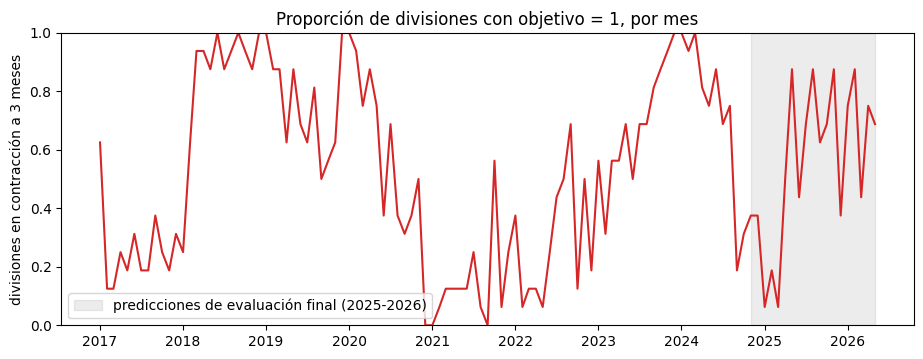

In [18]:
mensual = modelable.groupby("fecha")["objetivo"].mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(mensual.index, mensual.values, color="tab:red")
ax.axvspan(pd.Timestamp("2024-11-01"), mensual.index.max(), color="grey", alpha=0.15,
           label="predicciones de evaluación final (2025-2026)")
ax.set_ylabel("divisiones en contracción a 3 meses")
ax.set_title("Proporción de divisiones con objetivo = 1, por mes")
ax.set_ylim(0, 1)
ax.legend(loc="lower left")
plt.show()

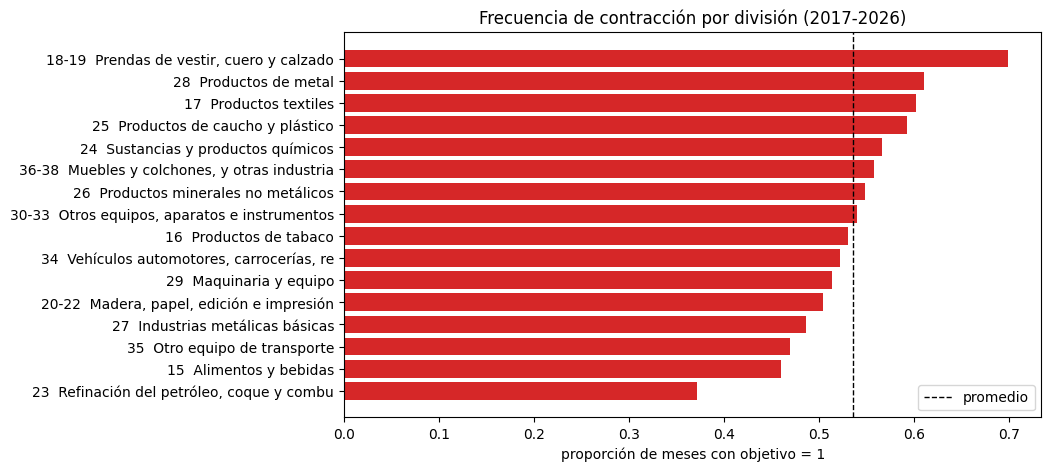

In [19]:
por_division = (modelable.groupby(["codigo_division", "division"])["objetivo"].mean()
                .sort_values().reset_index())
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(por_division["codigo_division"] + "  " + por_division["division"].str[:38],
        por_division["objetivo"], color="tab:red")
ax.axvline(modelable["objetivo"].mean(), color="black", linestyle="--", linewidth=1, label="promedio")
ax.set_xlabel("proporción de meses con objetivo = 1")
ax.set_title("Frecuencia de contracción por división (2017-2026)")
ax.legend()
plt.show()

## 5. Disponibilidad temporal de los datos

La devolución de la Entrega 1 marcó tres puntos, que quedan resueltos así:

**a) El resultado de cada fila no se conoce enseguida.** El IPI del mes *t* se publica en el mes *t+2*. Por eso cada fila tiene:
- `mes_decision` = *t+2*: cuando se publica el IPI de *t* y se hace la predicción. En ese momento ya están publicados el tipo de cambio, la BADLAR y la balanza comercial de *t*; la capacidad instalada se toma de *t-1* por prudencia.
- `mes_etiqueta_conocida` = *t+5*: cuando se publica el IPI de *t+3* y se puede verificar si hubo contracción.

Para simular que estamos al comienzo de 2025, el entrenamiento solo puede incluir filas cuyo resultado se conocía **antes** de enero de 2025.

**b) Un mismo mes no se reparte entre entrenamiento y validación.** Todas las separaciones se hacen filtrando por fecha, nunca por posición de fila, así las 16 divisiones de un mes siempre quedan juntas.

**c) Predicciones sin resultado todavía.** Las filas de junio a agosto de 2026 quedan como *pendientes*: no se usan ni para entrenar ni para evaluar.

Ejemplo con una fila de diciembre de 2024:

In [20]:
tabla.loc[(tabla["fecha"] == "2024-12-01") & (tabla["codigo_division"] == "15"),
          ["fecha", "division", "mes_decision", "mes_etiqueta_conocida", "objetivo"]]

,fecha,division,mes_decision,mes_etiqueta_conocida,objetivo
107,2024-12-01,Alimentos y bebidas,2025-02-01,2025-05-01,0.0


El dato de diciembre de 2024 se publica en febrero de 2025, y el resultado (IPI de marzo de 2025) recién se conoce en mayo de 2025. Esa fila **no** puede estar en el entrenamiento de un modelo que se usa desde enero de 2025.

Las funciones de `src/particiones.py` aplican estas reglas:

In [21]:
from particiones import separar_por_corte, cortes_validacion, comprobar_meses_enteros

con_variacion = tabla[tabla["ipi_var_ia"].notna()]
entrenamiento, evaluacion, pendientes = separar_por_corte(con_variacion, corte="2025-01-01")
resumen = pd.DataFrame({
    "filas": [len(entrenamiento), len(evaluacion), len(pendientes)],
    "meses": [c["fecha"].nunique() for c in (entrenamiento, evaluacion, pendientes)],
    "desde": [c["fecha"].min().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
    "hasta": [c["fecha"].max().strftime("%m/%Y") for c in (entrenamiento, evaluacion, pendientes)],
}, index=["entrenamiento", "evaluación final", "pendientes"])
print("¿Algún mes repartido entre conjuntos?", not comprobar_meses_enteros(entrenamiento, evaluacion, pendientes))
resumen

¿Algún mes repartido entre conjuntos? False


,filas,meses,desde,hasta
entrenamiento,1456,91,01/2017,07/2024
evaluación final,304,19,11/2024,05/2026
pendientes,48,3,06/2026,08/2026


- **Entrenamiento:** datos de enero 2017 a julio 2024 (el último resultado conocido antes de enero 2025 es el de julio 2024, publicado en diciembre 2024).
- **Evaluación final:** predicciones hechas desde enero de 2025 (datos de noviembre 2024 en adelante) cuyo resultado ya se observó.
- Las filas de agosto a octubre de 2024 quedan afuera de ambos: sus predicciones se hicieron en 2024, pero sus resultados se conocieron recién en 2025.

Para elegir modelos y variables se usa **validación temporal dentro del entrenamiento**, con la misma regla en cada corte:

In [22]:
filas = []
for corte, ent, val in cortes_validacion(entrenamiento, ["2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"]):
    comprobar_meses_enteros(ent, val)
    filas.append({"corte": f"{corte:%m/%Y}", "entrenamiento hasta": f"{ent['fecha'].max():%m/%Y}",
                  "filas entrenamiento": len(ent),
                  "validación": f"{val['fecha'].min():%m/%Y} a {val['fecha'].max():%m/%Y}",
                  "filas validación": len(val)})
pd.DataFrame(filas)

,corte,entrenamiento hasta,filas entrenamiento,validación,filas validación
0,01/2021,07/2020,688,11/2020 a 10/2021,192
1,01/2022,07/2021,880,11/2021 a 10/2022,192
2,01/2023,07/2022,1072,11/2022 a 10/2023,192
3,01/2024,07/2023,1264,11/2023 a 07/2024,144


## 6. Modelo de referencia

La referencia predice que **dentro de 3 meses la división va a estar igual que en el último dato publicado**: si hoy está en contracción, predice contracción. Como cada fila representa el momento en que se publica el IPI de *t*, "hoy" es `contraccion_hoy` (IPI de *t* contra *t-12*), que es justamente la última situación conocida en `mes_decision`.

Su desempeño en los cortes de validación (dentro del entrenamiento) da la vara que tendrán que superar los modelos:

In [23]:
def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    vp = ((pred == 1) & (real == 1)).sum()
    fp = ((pred == 1) & (real == 0)).sum()
    fn = ((pred == 0) & (real == 1)).sum()
    precision = vp / (vp + fp) if vp + fp else np.nan
    recall = vp / (vp + fn) if vp + fn else np.nan
    return {"exactitud": (real == pred).mean(), "precisión": precision, "recall": recall,
            "F1": 2 * precision * recall / (precision + recall)}

filas = []
for corte, ent, val in cortes_validacion(entrenamiento, ["2021-01-01", "2022-01-01", "2023-01-01", "2024-01-01"]):
    filas.append({"corte": f"{corte:%m/%Y}", **metricas(val["objetivo"], val["contraccion_hoy"])})
referencia = pd.DataFrame(filas).set_index("corte")
referencia.loc["promedio"] = referencia.mean()
referencia.round(3)

,exactitud,precisión,recall,F1
corte,,,,
01/2021,0.745,0.263,0.323,0.290
01/2022,0.682,0.342,0.265,0.299
01/2023,0.536,0.617,0.523,0.566
01/2024,0.840,0.907,0.914,0.911
promedio,0.701,0.532,0.506,0.516


La referencia funciona muy bien cuando la industria está en una tendencia estable (corte 2024: F1 = 0,91, porque casi todas las divisiones siguen en contracción) y muy mal en los **cambios de ciclo** (cortes 2021 y 2022: F1 ≈ 0,30, la salida de la recesión de 2020). Justamente en los cambios de ciclo es donde un modelo con información externa podría aportar.

## 7. Relación entre predictoras y variable objetivo (solo entrenamiento)

Siguiendo la devolución, el objetivo acá es **explorar** la relación de cada variable con la contracción, no descartar variables: una variable puede aportar en combinación con otras aunque sola no muestre relación. Todo se calcula **solo con el conjunto de entrenamiento**, para no mirar 2025-2026 antes de la evaluación final.

Dos medidas simples por variable:
- **AUC univariada:** si se ordenaran las filas solo por esa variable, ¿qué tan bien separa contracción de no contracción? 0,5 = nada; cuanto más lejos de 0,5 (hacia arriba o hacia abajo), más información. Debajo de 0,5 indica relación inversa.
- **Tasa de contracción por quintil:** se divide la variable en 5 grupos de igual tamaño y se mira qué proporción de cada grupo termina en contracción.

In [24]:
def auc_univariada(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    rangos = d["x"].rank()
    n1, n0 = (d["y"] == 1).sum(), (d["y"] == 0).sum()
    return (rangos[d["y"] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def tasa_por_quintil(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    grupos = pd.qcut(d["x"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
    return d.groupby(grupos, observed=True)["y"].mean()

exploracion = []
for v in PREDICTORAS:
    auc = auc_univariada(entrenamiento[v], entrenamiento["objetivo"])
    fila = {"variable": v, "AUC": auc, "distancia a 0,5": abs(auc - 0.5)}
    if entrenamiento[v].nunique() > 5:
        q = tasa_por_quintil(entrenamiento[v], entrenamiento["objetivo"])
        fila["contracción quintil más bajo"] = q.iloc[0]
        fila["contracción quintil más alto"] = q.iloc[-1]
    exploracion.append(fila)
exploracion = pd.DataFrame(exploracion).set_index("variable").sort_values("distancia a 0,5", ascending=False)
exploracion.round(3)

,AUC,"distancia a 0,5",contracción quintil más bajo,contracción quintil más alto
variable,,,,
impo_var_ia,0.231,0.269,0.829,0.189
tc_var_ia,0.766,0.266,0.236,0.863
ipi_var_ia,0.236,0.264,0.853,0.213
uci_general_dif_ia,0.270,0.230,0.826,0.309
ipi_var_ia_lag1,0.278,0.222,0.788,0.274
uci_bloque_dif_ia,0.287,0.213,0.767,0.240
contraccion_hoy,0.696,0.196,NaN,NaN
ipi_var_ia_lag2,0.305,0.195,0.733,0.288
tc_var_3m,0.634,0.134,0.408,0.818


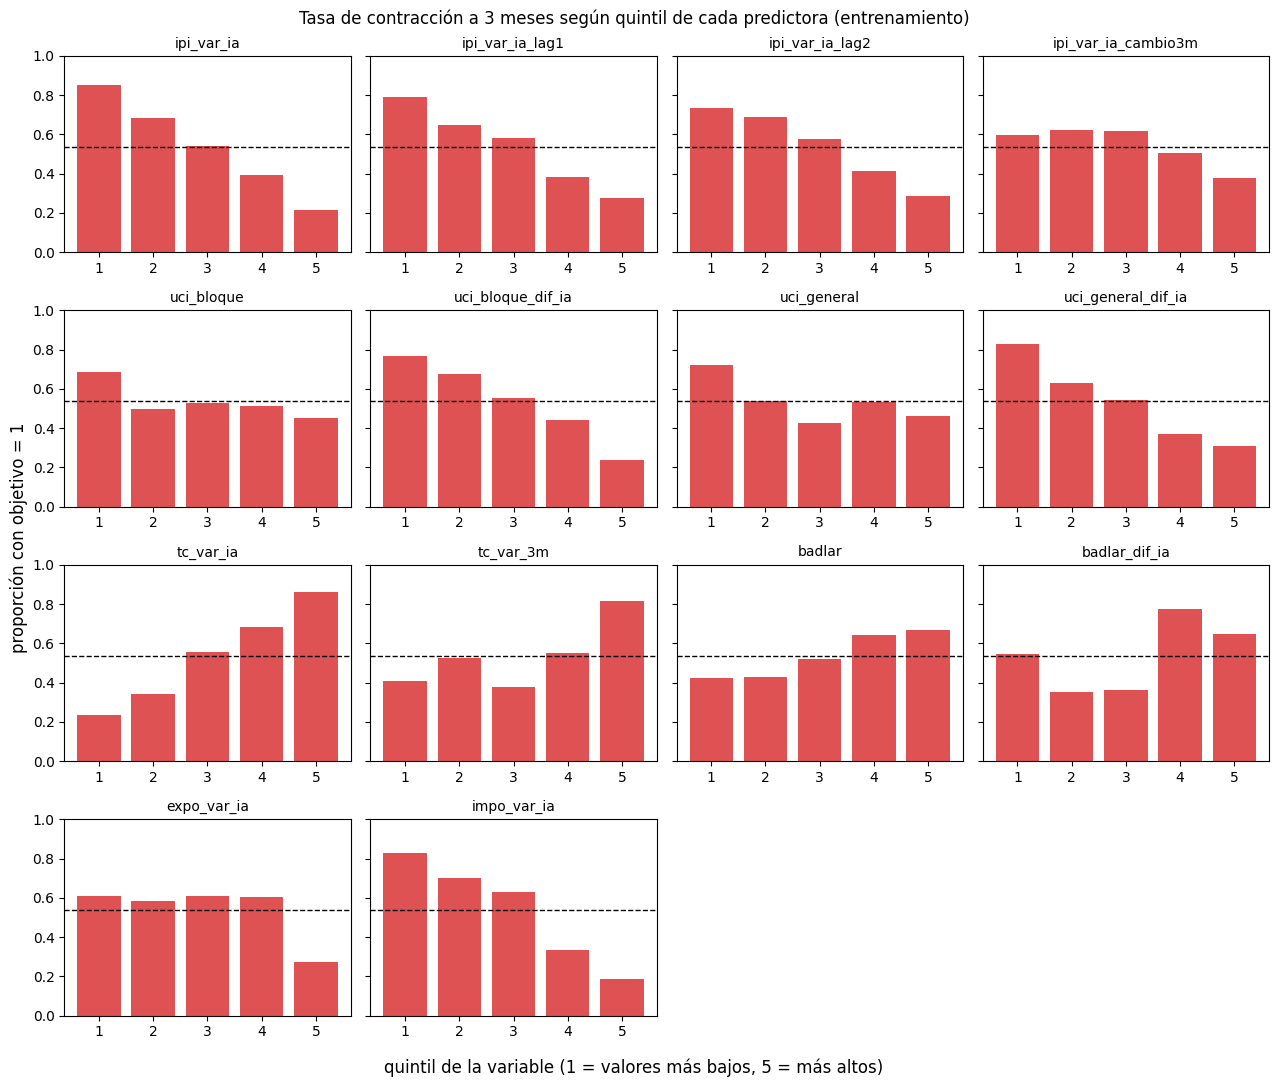

In [25]:
numericas = [v for v in PREDICTORAS if entrenamiento[v].nunique() > 5]
fig, ejes = plt.subplots(4, 4, figsize=(13, 11), sharey=True)
base = entrenamiento["objetivo"].mean()
for ax, v in zip(ejes.flat, numericas):
    q = tasa_por_quintil(entrenamiento[v], entrenamiento["objetivo"])
    ax.bar(q.index.astype(str), q.values, color="tab:red", alpha=0.8)
    ax.axhline(base, color="black", linestyle="--", linewidth=1)
    ax.set_title(v, fontsize=10)
    ax.set_ylim(0, 1)
for ax in ejes.flat[len(numericas):]:
    ax.axis("off")
fig.supxlabel("quintil de la variable (1 = valores más bajos, 5 = más altos)")
fig.supylabel("proporción con objetivo = 1")
fig.suptitle("Tasa de contracción a 3 meses según quintil de cada predictora (entrenamiento)")
fig.tight_layout()
plt.show()

**Lectura de los resultados:**

- **Las variables del propio IPI** son las más informativas, como era esperable: cuando la variación interanual actual está en el quintil más bajo, el 85% termina en contracción a 3 meses; en el más alto, el 21%. La señal se debilita con el rezago (`lag1`, `lag2`), así que lo más reciente pesa más.
- **La capacidad instalada** informa a través de su **cambio interanual** (`uci_bloque_dif_ia`, `uci_general_dif_ia`, AUC ≈ 0,27-0,29) mucho más que por su **nivel** (`uci_bloque`, `uci_general`, AUC ≈ 0,41-0,43). Una capacidad que cae respecto al año anterior anticipa contracción.
- **Tipo de cambio**: su variación interanual muestra la relación más fuerte entre las variables externas (AUC 0,77): las devaluaciones fuertes preceden contracciones.
- **Importaciones**: su caída interanual también se asocia a contracción (AUC 0,23), coherente con que la industria usa insumos importados.
- **BADLAR y exportaciones** muestran relaciones más débiles.

**Precaución importante:** las variables macro (tipo de cambio, tasa, balanza) tienen **un solo valor por mes**, igual para las 16 divisiones. Su relación con el objetivo se apoya en pocos episodios (las recesiones de 2018-2019 y 2023-2024), así que su AUC está más expuesta al azar que la de las variables por división. La validación temporal va a mostrar si esa relación se sostiene fuera de los años en que se observó.

In [26]:
contraccion = entrenamiento.groupby("contraccion_hoy")["objetivo"].agg(["count", "mean"])
contraccion.index = ["no está en contracción hoy", "está en contracción hoy"]
contraccion.columns = ["filas", "proporción en contracción a 3 meses"]
contraccion.round(3)

,filas,proporción en contracción a 3 meses
no está en contracción hoy,678,0.327
está en contracción hoy,778,0.719


Estar en contracción hoy eleva la probabilidad de contracción a 3 meses del 33% al 72%: la inercia es fuerte, y por eso la referencia es exigente.

### ¿La capacidad instalada del bloque informa en todas las divisiones?

Se repite la AUC de `uci_bloque_dif_ia` división por división, para revisar en especial las asignaciones aproximadas (18-19 y 36-38).

In [27]:
por_div = (entrenamiento.groupby(["codigo_division", "bloque_capacidad"])
           .apply(lambda g: auc_univariada(g["uci_bloque_dif_ia"], g["objetivo"]), include_groups=False)
           .rename("AUC uci_bloque_dif_ia").reset_index())
por_div.round(3)

,codigo_division,bloque_capacidad,AUC uci_bloque_dif_ia
0,15,Productos alimenticios y bebidas,0.349
1,16,Productos del tabaco,0.648
2,17,Productos textiles,0.266
3,18-19,Productos textiles,0.205
4,20-22,Papel y cartón + Edición e impresión,0.292
5,23,Refinación del petróleo,0.348
6,24,Sustancias y productos químicos,0.439
7,25,Productos de caucho y plástico,0.256
8,26,Productos minerales no metálicos,0.139
9,27,Industrias metálicas básicas,0.241


### Correlación entre predictoras

Variables muy correlacionadas entre sí aportan información repetida. Esto es importante para la regresión logística (coeficientes inestables) y menos para los árboles.

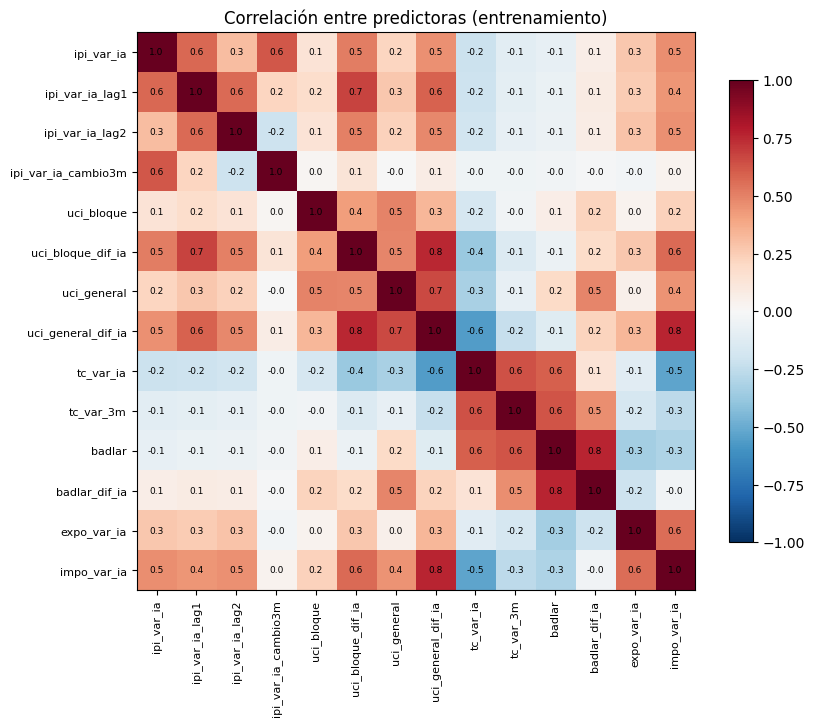

In [28]:
corr = entrenamiento[numericas].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=90, fontsize=8)
ax.set_yticks(range(len(numericas)), numericas, fontsize=8)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación entre predictoras (entrenamiento)")
plt.show()

In [29]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("correlación").reset_index())
pares.columns = ["variable 1", "variable 2", "correlación"]
pares["abs"] = pares["correlación"].abs()
pares.sort_values("abs", ascending=False).head(8).drop(columns="abs").round(2)

,variable 1,variable 2,correlación
85,badlar,badlar_dif_ia,0.76
75,uci_general_dif_ia,impo_var_ia,0.76
56,uci_bloque_dif_ia,uci_general_dif_ia,0.75
16,ipi_var_ia_lag1,uci_bloque_dif_ia,0.68
63,uci_general,uci_general_dif_ia,0.66
76,tc_var_ia,tc_var_3m,0.64
81,tc_var_3m,badlar,0.63
2,ipi_var_ia,ipi_var_ia_cambio3m,0.62


En la tabla por división, la capacidad del bloque tiene AUC menor a 0,5 (relación esperada: cae la capacidad, sigue contracción) en **15 de las 16 divisiones**. Las asignaciones aproximadas funcionan razonablemente: **18-19** con el bloque textil da 0,21 (de las más fuertes) y **36-38** con el nivel general da 0,36. La excepción es **tabaco** (0,65), un sector pequeño y con pocas plantas, donde la capacidad se mueve por razones propias.

En las correlaciones, los pares más altos son BADLAR con su variación (0,76), la capacidad general con las importaciones (0,76) y la capacidad del bloque con la general (0,75). Ninguna llega a ser redundante del todo, pero para la regresión logística convendrá no incluir todas juntas o usar regularización.

## 8. Resumen

**Dataset final** (`data/processed/tabla_modelo.csv`):
- **2.048 instancias** (16 divisiones × 128 meses, enero 2016 a agosto 2026), de las cuales **1.808 son modelables** (enero 2017 a mayo 2026).
- **24 columnas**: 4 de identificación, 3 de control temporal, 15 predictoras numéricas (14 continuas y una binaria) y la variable objetivo binaria.
- **Clases**: 53,6% de contracción en total, con mucha variación entre años.

**Separación temporal** (devolución de la Entrega 1):
- Entrenamiento: 1.456 filas (01/2017 a 07/2024), solo con resultados conocidos antes de enero 2025.
- Evaluación final: 304 filas (predicciones de 2025-2026 con resultado observado).
- Pendientes: 48 filas (junio a agosto 2026), sin resultado todavía.
- Validación temporal con 4 cortes dentro del entrenamiento, sin repartir meses.

**Exploración (solo entrenamiento)**: las variables del IPI, el cambio interanual de la capacidad instalada, el tipo de cambio y las importaciones muestran relación con la contracción a 3 meses. Que aporten **más allá de la referencia** se va a evaluar en la próxima etapa, entrenando los modelos y comparándolos con ella en los cortes de validación y finalmente en 2025-2026.

**Próximos pasos:**
1. Tratar los extremos de la pandemia para la regresión logística.
2. Entrenar los modelos (regresión logística, árbol, random forest, gradient boosting, KNN) con validación temporal.
3. Seleccionar variables dentro del entrenamiento y comparar contra la referencia.
4. Evaluación final en 2025-2026.